In [1]:
import numpy as np
import matplotlib.pyplot as plt
import fastplotlib as fpl
import scipy
from scipy import linalg
import seaborn as sns
from matplotlib import pyplot as plt
import fastplotlib as fpl
import tifffile

%matplotlib inline

rendercanvas version from git (2.0.0) and __version__ (2.0.3) don't match.
Unable to find extension: VK_EXT_swapchain_colorspace


Image(value=b'\x89PNG\r\n\x1a\n\x00\x00\x00\rIHDR\x00\x00\x01,\x00\x00\x007\x08\x06\x00\x00\x00\xb6\x1bw\x99\x…

Valid,Device,Type,Backend,Driver
✅ (default),AMD RADV POLARIS10 (ACO),DiscreteGPU,Vulkan,Mesa 20.3.5 (ACO)
❗ limited,"llvmpipe (LLVM 11.0.1, 256 bits)",CPU,Vulkan,Mesa 20.3.5 (LLVM 11.0.1)
✅,NVIDIA GeForce RTX 3080,DiscreteGPU,Vulkan,530.30.02
❌,"Radeon RX 570 Series (POLARIS10, DRM 3.40.0, 5.10.0-21-amd64, LLVM 11.0.1)",Unknown,OpenGL,4.6 (Core Profile) Mesa 20.3.5


pygfx version from git (0.9.0) and __version__ (0.10.0) don't match.


In [2]:
from skimage.transform import downscale_local_mean

In [22]:
path = "/home/kushal/repos/td-svd-sandbox/vaz_crop_2.tif"

movie = tifffile.imread(path)#[:, ::2, ::2]

# Convert the data type to float32
movie = movie.astype(np.float32)

In [23]:
movie.shape

(1730, 96, 70)

In [24]:
movie = downscale_local_mean(movie, factors=(1, 2, 2)).copy()
movie.shape

(1730, 48, 35)

RFBOutputContext()

/home/kushal/repos/fastplotlib/fastplotlib/graphics/features/_base.py:18: UserWarning: casting float64 array to float32
  warn(f"casting {array.dtype} array to float32")


JupyterRenderCanvas(css_height='300.0px', css_width='500.0px')
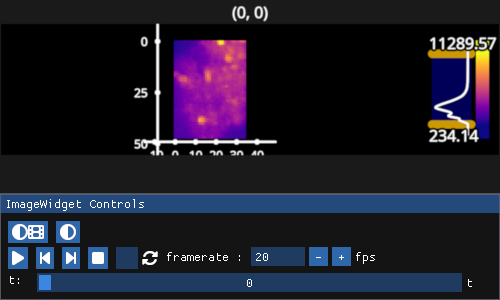

In [25]:
fpl.ImageWidget(movie).show()

In [26]:
from skophys.preprocessing import UnVectorizer, Vectorizer

unvec = UnVectorizer(movie.shape[1:])
vectorizer = Vectorizer()
X = vectorizer.fit_transform(movie).T

In [27]:
n_pixels = X.shape[1]
n_time_steps = X.shape[0]

P = np.zeros((n_time_steps-1,n_pixels))
F = np.zeros((n_time_steps-1,n_pixels))
for row in range(0,n_time_steps-1):
    P[row,:] = X[row,:]
    F[row,:] = X[row+1,:]

print (f"X.shape = {X.shape}")
print (f"P.shape = {P.shape}")
print (f"F.shape = {F.shape}")

X.shape = (1730, 1680)
P.shape = (1729, 1680)
F.shape = (1729, 1680)


In [28]:
def centered_matrix(X):    
    X_mean = X.mean(axis=1, keepdims=True) # has a shape of T x 1
    print (f"X_mean.shape = {X_mean.shape}")

    return X - X_mean

In [29]:
Pc = centered_matrix(P)
Fc = centered_matrix(F)

X_mean.shape = (1729, 1)
X_mean.shape = (1729, 1)


In [30]:
def eigen_decomposition(M):
    # output eigenvalues and eigenvectors sorted by eigenvalues
    
    eigenvalues, eigenvectors = np.linalg.eig(M)
    eigenvalues = np.real(eigenvalues)
    eigenvectors = np.real(eigenvectors)
    
    sorted_indices = np.argsort(eigenvalues)[::-1]
    eigenvalues = eigenvalues[sorted_indices]
    eigenvectors = eigenvectors[:, sorted_indices]
    print (f"eigenvectors.shape = {eigenvectors.shape}")

    return eigenvalues, eigenvectors

In [31]:
def covariance_matrix(X):
    # we assume X has a shape (T,N)
    # N = number of features
    # T = number of samples
    
    N = X.shape[1]
    COV = X.T @ X / float(N)
    
    return COV

In [32]:
def whitened_matrix(X):
    # we assume X has a shape (T,N)
    # N = number of features
    # T = number of samples
    
    COV = covariance_matrix(X)
    S, U = eigen_decomposition(COV)

    # Epsilon is added to the eigenvalues to prevent division by zero
    epsilon = 1e-5
    inv_sqrt_S = np.diag(1.0 / np.sqrt(S + epsilon))

    # whitening matrix
    W = U @ inv_sqrt_S @ U.T

    # whitened data
    Xw = X @ W

    return Xw

In [33]:
Pw = whitened_matrix(P)
Fw = whitened_matrix(F)
print (f"P.shape = {P.shape}")
print (f"Pw.shape = {Pw.shape}")

# verify that Pw is whitened data
COV = covariance_matrix(Pw)
print (COV)

eigenvectors.shape = (1680, 1680)
eigenvectors.shape = (1680, 1680)
P.shape = (1729, 1680)
Pw.shape = (1729, 1680)
[[ 9.99999909e-01 -1.25376366e-08  6.75552691e-09 ... -7.09577260e-10
  -5.41943120e-10 -1.42752876e-08]
 [-1.25376366e-08  9.99999893e-01  2.52117129e-09 ... -3.93559231e-09
   1.27583744e-08 -1.90983374e-08]
 [ 6.75552691e-09  2.52117129e-09  9.99999942e-01 ... -1.85084689e-08
  -8.47634355e-10  7.98367759e-09]
 ...
 [-7.09577260e-10 -3.93559231e-09 -1.85084689e-08 ...  9.99999923e-01
   7.46701358e-09  1.07088056e-08]
 [-5.41943120e-10  1.27583744e-08 -8.47634355e-10 ...  7.46701358e-09
   9.99999931e-01  1.56030908e-08]
 [-1.42752876e-08 -1.90983374e-08  7.98367759e-09 ...  1.07088056e-08
   1.56030908e-08  9.99999949e-01]]


In [34]:
Z = np.hstack((Pw, Fw))
ZTZ = Z.T @ Z

In [35]:
k = 32

In [36]:
H_init = 2 * np.sqrt(np.mean(np.mean(ZTZ) / k)) * np.random.rand(ZTZ.shape[0], k)

In [37]:
from tqdm.notebook import tqdm

eta = 5e-1
error_stop = 1e-4
error_log = np.zeros(20_000)

Y = H_init.T
# Y = np.abs(Sk @ Uk.T)

epsilon = 1e-5
epsilon_mtx = np.ones_like(Y@Y.T@Y) * epsilon

beta = 0.01
# beta = 1.0
# beta = 100.300300300300
for n_iter in tqdm(range(1_000)):
    Y_old = Y.copy()

    gamma = Y_old @ ZTZ / (beta * Y_old @ Y_old.T @ Y_old + epsilon_mtx)
    Y = Y_old * (1-eta) + eta * Y_old * gamma

    Y = Y.clip(0)  

    er = np.divide(np.abs(Y - Y_old), np.abs(Y_old + 1e-2)).max() / eta
    error_log[n_iter] = er
    # print (f"er = {er}")

    if er < error_stop:
        break

  0%|          | 0/1000 [00:00<?, ?it/s]

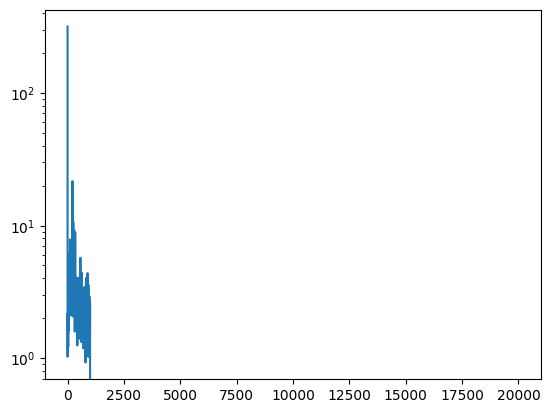

In [38]:
plt.plot(error_log)
plt.semilogy()
plt.show()

In [39]:
Y1 = Y[:,:n_pixels]
Y2 = Y[:,n_pixels:]

images = np.zeros((k, *unvec.shape))
for entry in range(k):

    images[entry] = unvec.transform(Y1[entry, :] + Y2[entry, :])

RFBOutputContext()

JupyterRenderCanvas(css_height='1000.0px', css_width='800.0px')
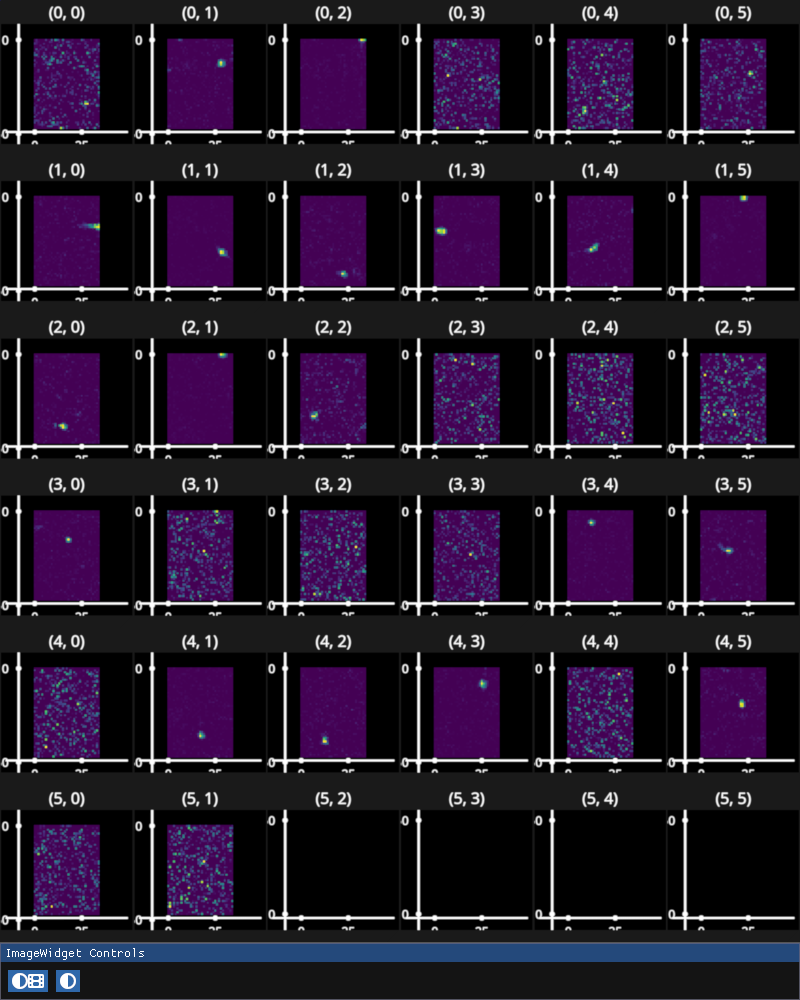

In [40]:
iw = fpl.ImageWidget([img for img in images], cmap="viridis", histogram_widget=False, figure_kwargs={"size": (800, 1000)})
for subplot in iw.figure:
    subplot.toolbar = False

iw.show()